# Tornado dimensionality reduction: Extra practice

Optional practice after the main Titanic lesson. The original dataset has 4,706 whole tracks from 2015-2018. This exercise uses a fixed 700-record sample for speed.

**Question:** What profiles appear across track size and starting location, and how do those profiles relate to EF rating?

The inputs are standardized log1p length, log1p width, starting latitude, and starting longitude. EF rating, month, start-state labels, injuries, and fatalities are withheld. Longitude/latitude here are exploratory features, not a precise physical-distance model.

All four saved methods are supplied. The same UMAP-js versus Python umap-learn provenance note applies as in Titanic. See [run details](../run_details.qmd).


## Setup and prepared features

Keep missing EF ratings as missing. They do not prevent fitting these four complete input features.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

ROOT = Path.cwd()
if not (ROOT / "support/eda_helpers.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "support"))
from eda_helpers import prepare_titanic, prepare_tornadoes, load_saved, load_variant, plot_embedding

# False uses supplied runs and requires only the base environment.
# True recomputes nonlinear methods. First run: uv sync --extra recompute
RECOMPUTE = False

df, X, feature_names = prepare_tornadoes(ROOT, include_location=True)
embeddings = {} if RECOMPUTE else load_saved(ROOT, "tornadoes", X, df["tornado_id"])
print("Fixed practice sample:", len(df), "records")
print("Embedding features:", feature_names)


Fixed practice sample: 700 records
Embedding features: ['log1p_length', 'log1p_width', 'start_latitude', 'start_longitude']


## A familiar starting view

Compare size variables directly before interpreting their multivariable embedding. The transformations reduce domination by very large recorded tracks.


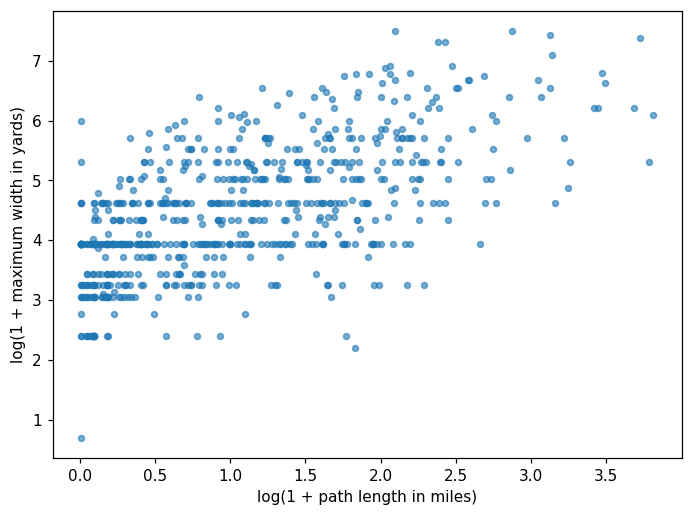

In [2]:
plt.scatter(np.log1p(df["path_length_miles"]), np.log1p(df["max_width_yards"]), s=15, alpha=0.6)
plt.xlabel("log(1 + path length in miles)")
plt.ylabel("log(1 + maximum width in yards)")
plt.tight_layout()
plt.show()


## PCA: a linear baseline

Apply the method using the Titanic notebook as a reference, or explore the supplied coordinates.


In [3]:
# TODO: Fit this method and replace its entry in embeddings.
# The supplied entry remains available for exploration.


## t-SNE: neighborhood similarities

Apply the method using the Titanic notebook as a reference, or explore the supplied coordinates.


In [4]:
# TODO: Fit this method and replace its entry in embeddings.
# The supplied entry remains available for exploration.


## UMAP: a neighborhood graph

Apply the method using the Titanic notebook as a reference, or explore the supplied coordinates.


In [5]:
# TODO: Fit this method and replace its entry in embeddings.
# The supplied entry remains available for exploration.


## PHATE: diffusion and broader structure

Apply the method using the Titanic notebook as a reference, or explore the supplied coordinates.


In [6]:
# TODO: Fit this method and replace its entry in embeddings.
# The supplied entry remains available for exploration.


## Investigate a question using color

Try ef_rating, month, path_length_miles, max_width_yards, start_state, or start_latitude. Which overlays describe features already used to construct the geometry? Which supply withheld information?


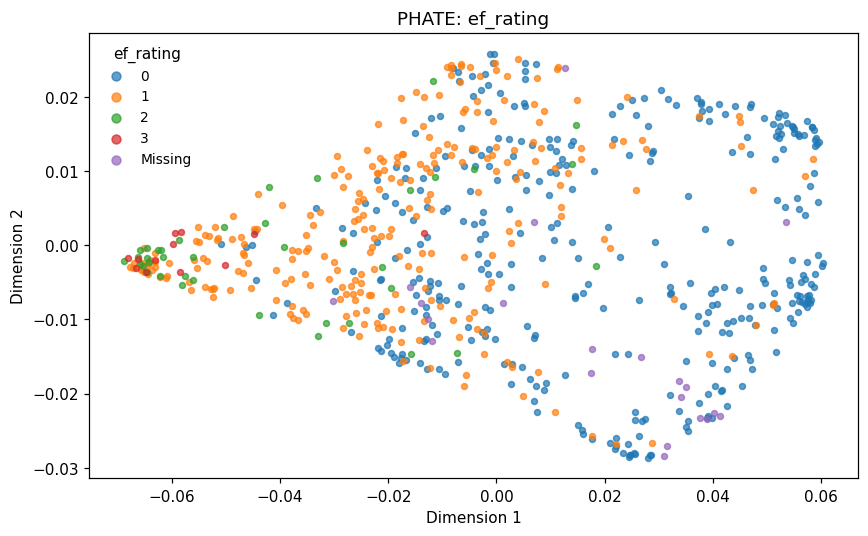

In [7]:
METHOD = "PHATE"
COLOR_BY = "ef_rating"
plot_embedding(embeddings[METHOD], df, COLOR_BY, f"{METHOD}: {COLOR_BY}")
plt.tight_layout()
plt.show()


## Return to original variables

Inspect the number of observed ratings before comparing sizes across EF categories. This is a descriptive comparison within the practice sample, not a population risk estimate.


In [8]:
# TODO: Choose a relevant original-variable comparison.
# Count the records used and explain any missing-value exclusions.


## Further practice

- Compare a size-only PCA with the size-and-location PCA. `prepare_tornadoes(ROOT, include_location=False)` provides the two size inputs. Why is a direct two-variable scatter already informative in that case?
- Explain how including geography influences the meaning of a visible grouping.
- Identify a question this dataset cannot answer without additional information.

Saved coordinates are tied to the supplied feature matrix. Changed preparation requires recomputation, not reuse of the old cache.
